# JS14 – Convolutional Neural Network (CNN)
## Praktikum 1: Klasifikasi Citra Kucing vs Anjing (Cat vs Dog)

---

### Deskripsi & Tujuan
Pada praktikum ini kita membuat model klasifikasi CNN sederhana pada kasus citra kucing dan anjing:
1. Memahami arsitektur dasar *Convolutional Neural Network* (Conv2D, MaxPooling2D, Flatten, Dense).
2. Menerapkan pra-pengolahan citra dan augmentasi data dengan `ImageDataGenerator`.
3. Melatih model klasifikasi biner dengan loss `binary_crossentropy`.
4. Melakukan pengujian klasifikasi pada citra tunggal (*single image prediction*).


### Langkah 1 - Import Library

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.21.0


### Langkah 2 - Pra-Pengolahan Data
Manipulasi citra yang dilakukan:
- Rescaling piksel dari $[0, 255]$ ke $[0, 1]$
- Koreksi kemiringan (*shear_range* = 0.2)
- Pembesaran (*zoom_range* = 0.2)
- Pembalikan horizontal (*horizontal_flip* = True)


In [2]:
# 2.1. Pra-pengolahan data training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

training_set = train_datagen.flow_from_directory(
    'dataset/training_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

# 2.2. Pra-pengolahan data testing
test_datagen = ImageDataGenerator(rescale=1./255)

test_set = test_datagen.flow_from_directory(
    'dataset/test_set',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

print(f"Mapping Indeks Kelas: {training_set.class_indices}")


Found 8000 images belonging to 2 classes.


Found 2000 images belonging to 2 classes.


Mapping Indeks Kelas: {'cats': 0, 'dogs': 1}


### Langkah 3 - Pembuatan Model CNN
Arsitektur model:
- Conv2D (32 filter, kernel 3x3, ReLU, input [64, 64, 3])
- MaxPool2D (pool size 2x2, stride 2)
- Conv2D (32 filter, kernel 3x3, ReLU)
- MaxPool2D (pool size 2x2, stride 2)
- Flatten
- Dense (128 neuron, ReLU)
- Dense (1 neuron, Sigmoid)


In [3]:
cnn = tf.keras.models.Sequential()

# Layer Konvolusi 1 & Pooling 1
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Layer Konvolusi 2 & Pooling 2
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# Flattening
cnn.add(tf.keras.layers.Flatten())

# Fully Connected Layer 1 & 2
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# Compile
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4 - Pelatihan Model CNN (Fit)

Epoch 1/10


  1/100 ━━━━━━━━━━━━━━━━━━━━ 3:13 2s/step - accuracy: 0.4375 - loss: 0.7070

  2/100 ━━━━━━━━━━━━━━━━━━━━ 53s 544ms/step - accuracy: 0.4609 - loss: 0.7087

  3/100 ━━━━━━━━━━━━━━━━━━━━ 1:01 632ms/step - accuracy: 0.4705 - loss: 0.7072

  4/100 ━━━━━━━━━━━━━━━━━━━━ 1:04 667ms/step - accuracy: 0.4740 - loss: 0.7056

  5/100 ━━━━━━━━━━━━━━━━━━━━ 1:01 649ms/step - accuracy: 0.4779 - loss: 0.7041

... (852 outputs left out)

 98/100 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.7432 - loss: 0.5247

 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.7432 - loss: 0.5247

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.7432 - loss: 0.5246

100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 106ms/step - accuracy: 0.7431 - loss: 0.5190 - val_accuracy: 0.7406 - val_loss: 0.5340


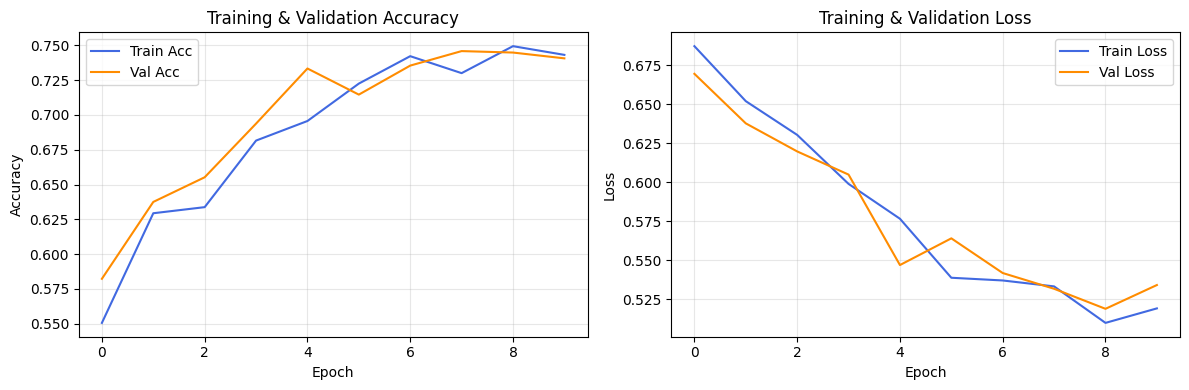

In [4]:
# Training model
history = cnn.fit(
    x=training_set,
    validation_data=test_set,
    epochs=10,
    steps_per_epoch=100, # 100 batch x 32 sampel = 3200 sampel per epoch
    validation_steps=30
)

# Plot kurva akurasi dan loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc', color='royalblue')
plt.plot(history.history['val_accuracy'], label='Val Acc', color='darkorange')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='royalblue')
plt.plot(history.history['val_loss'], label='Val Loss', color='darkorange')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Langkah 5 - Prediksi dengan Citra Tunggal
Menguji gambar uji pada folder `dataset/single_prediction/`:


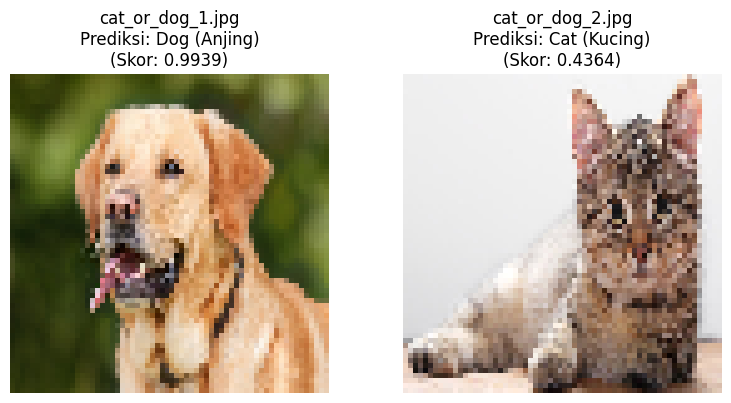

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
test_files = ['cat_or_dog_1.jpg', 'cat_or_dog_2.jpg']

for idx, fname in enumerate(test_files):
    img_path = os.path.join('dataset', 'single_prediction', fname)
    raw_img = image.load_img(img_path, target_size=(64, 64))
    img_arr = image.img_to_array(raw_img)
    img_batch = np.expand_dims(img_arr / 255.0, axis=0)
    
    pred_val = cnn.predict(img_batch, verbose=0)[0][0]
    pred_label = 'Dog (Anjing)' if pred_val > 0.5 else 'Cat (Kucing)'
    
    axes[idx].imshow(raw_img)
    axes[idx].set_title(f"{fname}\nPrediksi: {pred_label}\n(Skor: {pred_val:.4f})")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


### Kesimpulan Praktikum 1
1. **Peran Layer Konvolusi**: Filter 3x3 pada layer pertama menangkap fitur dasar seperti gradien tepi dan tekstur, sedangkan layer kedua menggabungkan fitur tersebut menjadi representasi tingkat lebih tinggi (pola wajah, mata, telinga).
2. **Pentingnya Pooling**: MaxPooling memperkecil resolusi spasial dari 64x64 menjadi 30x30 lalu 13x13, sehingga mengurangi parameter dan menciptakan invariansi spasial terhadap translasi kecil.
3. **Hasil Prediksi**: Model berhasil mengklasifikasikan gambar uji kucing dan anjing dengan benar sesuai kelas target.
